# Loading Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 6)
sns.set_style('darkgrid')

In [2]:
df = pd.read_csv('city_events.csv')

In [3]:
df

,event_id,event_name,event_type,district_id,start_timestamp,end_timestamp,expected_attendance,actual_attendance,event_impact_level
0,EVT_0001,Conference 2025,Conference,D08,2025-09-21 16:00:00,2025-09-21 19:00:00,6468,6488,Medium
1,EVT_0002,Marathon 2023,Marathon,D18,2023-04-12 18:00:00,2023-04-12 22:00:00,78082,58674,Extreme
2,EVT_0003,Marathon 2024,Marathon,D01,2024-05-01 18:00:00,2024-05-01 22:00:00,29996,29136,High
3,EVT_0004,Conference 2025,Conference,D15,2025-05-12 11:00:00,2025-05-12 20:00:00,3032,2743,Low
4,EVT_0005,Political Event 2025,Political Event,D08,2025-12-12 13:00:00,2025-12-13 00:00:00,2771,2270,Low
...,...,...,...,...,...,...,...,...,...
295,EVT_0296,Public Holiday 2025,Public Holiday,D11,2025-08-22 10:00:00,2025-08-22 18:00:00,15498,14563,High
296,EVT_0297,Festival 2024,Festival,D08,2024-03-12 15:00:00,2024-03-12 20:00:00,23865,22773,High
297,EVT_0298,Public Holiday 2024,Public Holiday,D12,2024-12-08 18:00:00,2024-12-08 21:00:00,21181,20860,High
298,EVT_0299,Conference 2023,Conference,D07,2023-07-02 13:00:00,2023-07-02 22:00:00,4456,4154,Medium


# Exploring Data

## Exploring columns and validating

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   event_id             300 non-null    str  
 1   event_name           300 non-null    str  
 2   event_type           300 non-null    str  
 3   district_id          300 non-null    str  
 4   start_timestamp      300 non-null    str  
 5   end_timestamp        300 non-null    str  
 6   expected_attendance  300 non-null    int64
 7   actual_attendance    300 non-null    int64
 8   event_impact_level   300 non-null    str  
dtypes: int64(2), str(7)
memory usage: 44.5 KB


### Converting timestamps to datetime

In [5]:
date_cols = ['start_timestamp', 'end_timestamp']
for col in date_cols:
    df[col] = pd.to_datetime(df[col], format='%Y-%m-%d %H:%M:%S' ,errors='coerce')

### Checking for duplicated primary key (and dropping duplicates if existed)

In [6]:
#Checking if there is duplicated primary key
df['event_id'].duplicated().sum()

np.int64(0)

### Understanding columns + feature engineering (if needed)

In [7]:
# Checking event names
df['event_name'].unique()

<ArrowStringArray>
[       'Conference 2025',          'Marathon 2023',          'Marathon 2024',
   'Political Event 2025',    'Public Holiday 2025',   'Political Event 2024',
            'Market 2025',        'Conference 2023',          'Festival 2023',
    'Public Holiday 2024',            'Market 2024',           'Concert 2025',
            'Parade 2024',    'Public Holiday 2023',          'Festival 2024',
   'Political Event 2023',    'Football Match 2023', 'Cultural Festival 2023',
    'Football Match 2025',           'Concert 2024', 'Cultural Festival 2025',
          'Festival 2025',            'Parade 2025',          'Marathon 2025',
        'Conference 2024',            'Parade 2023',            'Market 2023',
           'Concert 2023',    'Football Match 2024', 'Cultural Festival 2024']
Length: 30, dtype: str

In [8]:
# Extracting year from event name
df['year'] = df['event_name'].str.split(' ').str[-1]

In [9]:
# Checking the types and the most done type
df['event_type'].value_counts()

event_type
Public Holiday       38
Conference           36
Market               35
Parade               35
Marathon             31
Political Event      30
Cultural Festival    28
Concert              25
Festival             23
Football Match       19
Name: count, dtype: int64

In [10]:
# Validating the types are correct
df[df['event_name'].str[:-5] != df['event_type']]

,event_id,event_name,event_type,district_id,start_timestamp,end_timestamp,expected_attendance,actual_attendance,event_impact_level,year


In [11]:
# Validating the timestamps are correct
df[df['start_timestamp'] > df['end_timestamp']]

,event_id,event_name,event_type,district_id,start_timestamp,end_timestamp,expected_attendance,actual_attendance,event_impact_level,year


In [12]:
# Extracting duration from time stamps
df['duration_hours'] = (df['end_timestamp'] - df['start_timestamp']).dt.total_seconds() / 3600

In [13]:
# Extracting attendance rate from actual and expected
df['attendance_rate'] = df['actual_attendance'] / df['expected_attendance']

In [14]:
df['event_impact_level'].value_counts()

event_impact_level
High       134
Medium      72
Low         57
Extreme     37
Name: count, dtype: int64

In [15]:
# Checking for abnormal values
df.describe()

,start_timestamp,end_timestamp,expected_attendance,actual_attendance,duration_hours,attendance_rate
count,300,300,300.000000,300.00000,300.000000,300.000000
mean,2024-06-16 16:14:12,2024-06-16 23:03:48,22502.606667,20031.60000,6.826667,0.898063
min,2023-01-03 15:00:00,2023-01-03 23:00:00,1016.000000,859.00000,3.000000,0.628514
25%,2023-10-07 22:00:00,2023-10-08 01:15:00,5972.250000,5480.25000,5.000000,0.824965
50%,2024-06-13 22:00:00,2024-06-14 08:00:00,15562.000000,14753.00000,7.000000,0.901911
75%,2025-03-08 04:30:00,2025-03-08 14:45:00,34256.250000,29182.25000,9.000000,0.974562
max,2025-12-22 13:00:00,2025-12-22 23:00:00,79890.000000,77608.00000,11.000000,1.172985
std,NaN,NaN,20733.043514,18400.27457,2.581764,0.103409


## Checking nulls

In [16]:
# Checking for nulls
df.isnull().sum()

event_id               0
event_name             0
event_type             0
district_id            0
start_timestamp        0
end_timestamp          0
expected_attendance    0
actual_attendance      0
event_impact_level     0
year                   0
duration_hours         0
attendance_rate        0
dtype: int64

## Checking outliers

In [17]:
def find_outliers_iqr(df, column):
    Q1, Q3 = df[column].quantile(0.25), df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    return df[(df[column] < lower) | (df[column] > upper)]

for col in ['expected_attendance', 'actual_attendance', 'duration_hours', 'attendance_rate']:
    print(f'{col}: {len(find_outliers_iqr(df, col))}, mean: {df[col].mean():.2f}, above upper = {len(find_outliers_iqr(df, col)[df[col] > df[col].mean()])}, below lower = {len(find_outliers_iqr(df, col)[df[col] < df[col].mean()])}')

expected_attendance: 5, mean: 22502.61, above upper = 5, below lower = 0
actual_attendance: 11, mean: 20031.60, above upper = 11, below lower = 0
duration_hours: 0, mean: 6.83, above upper = 0, below lower = 0
attendance_rate: 0, mean: 0.90, above upper = 0, below lower = 0


## Validating Outliers

### Expected attendance

In [18]:
expected_outliers = find_outliers_iqr(df, 'expected_attendance')
expected_outliers
# It's normal value since all the outliers' impact level is extreme

,event_id,event_name,event_type,district_id,start_timestamp,end_timestamp,expected_attendance,actual_attendance,event_impact_level,year,duration_hours,attendance_rate
1,EVT_0002,Marathon 2023,Marathon,D18,2023-04-12 18:00:00,2023-04-12 22:00:00,78082,58674,Extreme,2023,4.0,0.751441
31,EVT_0032,Concert 2025,Concert,D15,2025-09-11 09:00:00,2025-09-11 17:00:00,77365,64957,Extreme,2025,8.0,0.839617
143,EVT_0144,Marathon 2023,Marathon,D05,2023-10-22 16:00:00,2023-10-23 03:00:00,79474,70737,Extreme,2023,11.0,0.890065
163,EVT_0164,Marathon 2024,Marathon,D07,2024-03-06 12:00:00,2024-03-06 17:00:00,79890,64138,Extreme,2024,5.0,0.802829
228,EVT_0229,Concert 2025,Concert,D17,2025-08-19 16:00:00,2025-08-20 00:00:00,79611,67299,Extreme,2025,8.0,0.845348


### Actual attendance

In [19]:
actual_outliers = find_outliers_iqr(df, 'actual_attendance')
actual_outliers
# It's normal value since all the outlier's impact level is extreme

,event_id,event_name,event_type,district_id,start_timestamp,end_timestamp,expected_attendance,actual_attendance,event_impact_level,year,duration_hours,attendance_rate
31,EVT_0032,Concert 2025,Concert,D15,2025-09-11 09:00:00,2025-09-11 17:00:00,77365,64957,Extreme,2025,8.0,0.839617
91,EVT_0092,Concert 2025,Concert,D10,2025-05-23 11:00:00,2025-05-23 22:00:00,65360,72081,Extreme,2025,11.0,1.102830
109,EVT_0110,Concert 2023,Concert,D08,2023-02-19 10:00:00,2023-02-19 17:00:00,69634,77608,Extreme,2023,7.0,1.114513
143,EVT_0144,Marathon 2023,Marathon,D05,2023-10-22 16:00:00,2023-10-23 03:00:00,79474,70737,Extreme,2023,11.0,0.890065
158,EVT_0159,Football Match 2024,Football Match,D14,2024-01-16 13:00:00,2024-01-16 22:00:00,69927,64868,Extreme,2024,9.0,0.927653
166,EVT_0167,Concert 2024,Concert,D14,2024-08-18 10:00:00,2024-08-18 15:00:00,70979,73308,Extreme,2024,5.0,1.032813
178,EVT_0179,Marathon 2023,Marathon,D02,2023-11-29 14:00:00,2023-11-29 19:00:00,71612,65615,Extreme,2023,5.0,0.916257
205,EVT_0206,Football Match 2023,Football Match,D07,2023-11-05 15:00:00,2023-11-05 23:00:00,69823,69013,Extreme,2023,8.0,0.988399
228,EVT_0229,Concert 2025,Concert,D17,2025-08-19 16:00:00,2025-08-20 00:00:00,79611,67299,Extreme,2025,8.0,0.845348
242,EVT_0243,Concert 2024,Concert,D02,2024-11-23 12:00:00,2024-11-23 18:00:00,73798,68500,Extreme,2024,6.0,0.928209


### Lower attendance than expected

In [20]:
expected_outliers[~expected_outliers['event_id'].isin(actual_outliers['event_id'])]
# Events that expected high attendance and didn't have that attendance

,event_id,event_name,event_type,district_id,start_timestamp,end_timestamp,expected_attendance,actual_attendance,event_impact_level,year,duration_hours,attendance_rate
1,EVT_0002,Marathon 2023,Marathon,D18,2023-04-12 18:00:00,2023-04-12 22:00:00,78082,58674,Extreme,2023,4.0,0.751441
163,EVT_0164,Marathon 2024,Marathon,D07,2024-03-06 12:00:00,2024-03-06 17:00:00,79890,64138,Extreme,2024,5.0,0.802829


### Higher attendance than expected

In [21]:
actual_outliers[~actual_outliers['event_id'].isin(expected_outliers['event_id'])]
# Events that had high attendance and didn't expect that attendance

,event_id,event_name,event_type,district_id,start_timestamp,end_timestamp,expected_attendance,actual_attendance,event_impact_level,year,duration_hours,attendance_rate
91,EVT_0092,Concert 2025,Concert,D10,2025-05-23 11:00:00,2025-05-23 22:00:00,65360,72081,Extreme,2025,11.0,1.102830
109,EVT_0110,Concert 2023,Concert,D08,2023-02-19 10:00:00,2023-02-19 17:00:00,69634,77608,Extreme,2023,7.0,1.114513
158,EVT_0159,Football Match 2024,Football Match,D14,2024-01-16 13:00:00,2024-01-16 22:00:00,69927,64868,Extreme,2024,9.0,0.927653
166,EVT_0167,Concert 2024,Concert,D14,2024-08-18 10:00:00,2024-08-18 15:00:00,70979,73308,Extreme,2024,5.0,1.032813
178,EVT_0179,Marathon 2023,Marathon,D02,2023-11-29 14:00:00,2023-11-29 19:00:00,71612,65615,Extreme,2023,5.0,0.916257
205,EVT_0206,Football Match 2023,Football Match,D07,2023-11-05 15:00:00,2023-11-05 23:00:00,69823,69013,Extreme,2023,8.0,0.988399
242,EVT_0243,Concert 2024,Concert,D02,2024-11-23 12:00:00,2024-11-23 18:00:00,73798,68500,Extreme,2024,6.0,0.928209
280,EVT_0281,Marathon 2023,Marathon,D18,2023-12-28 09:00:00,2023-12-28 20:00:00,70583,70367,Extreme,2023,11.0,0.996940


# Important KPIs

## Event counts per type

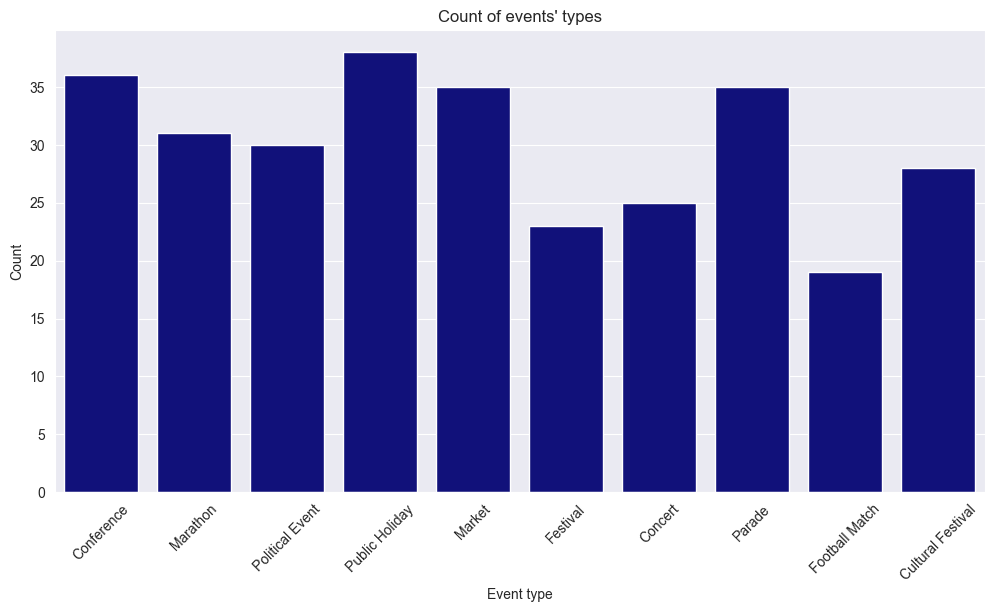

In [22]:
sns.countplot(df, x='event_type', color='darkblue')
plt.xticks(rotation=45)
plt.title("Count of events' types")
plt.xlabel('Event type')
plt.ylabel('Count')

plt.show()

## Attendance rate per event type

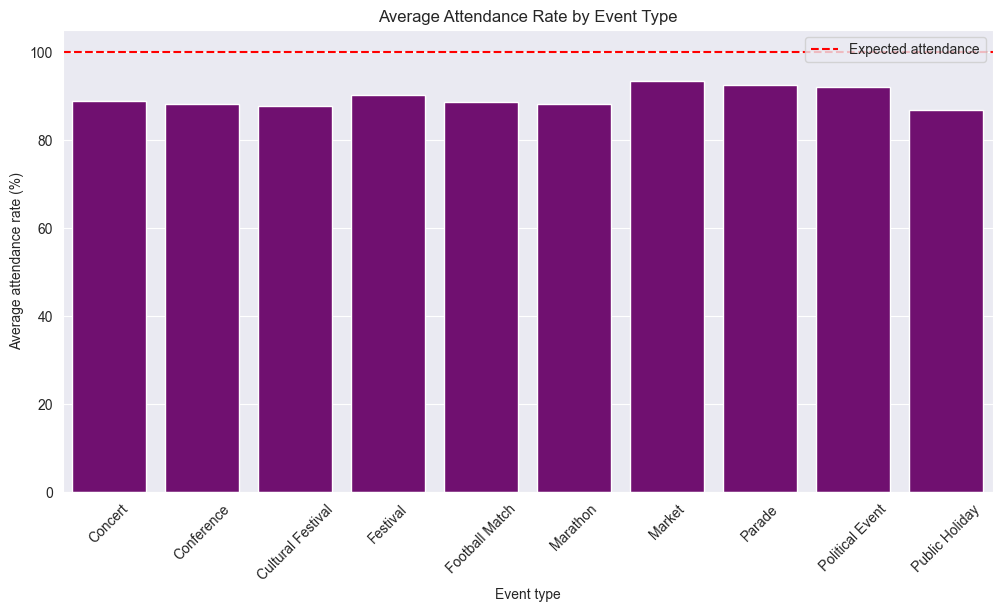

In [23]:
attendance_by_type = df.groupby('event_type').agg(average_rate=('attendance_rate', 'mean'))
attendance_by_type['average_rate_percent'] = attendance_by_type['average_rate'] * 100

sns.barplot(attendance_by_type, x='event_type', y='average_rate_percent', color='purple')

plt.axhline(100, color='red', linestyle='--', label='Expected attendance')
plt.title('Average Attendance Rate by Event Type')
plt.xlabel('Event type')
plt.ylabel('Average attendance rate (%)')
plt.xticks(rotation=45)
plt.legend()

plt.show()

## Events type made in each district

In [24]:
districts = pd.read_csv('districts.csv')
districts_events = df.merge(districts, on='district_id')
districts_events_matrix = districts_events.pivot_table(index='district_name', columns='event_type', aggfunc='size', fill_value=0)

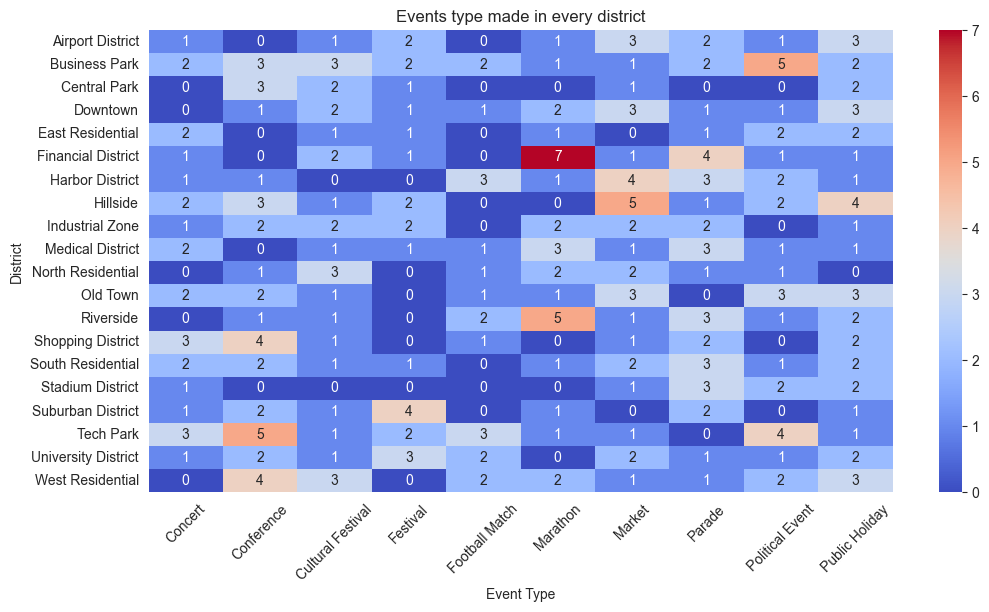

In [25]:
sns.heatmap(districts_events_matrix, annot=True, cmap='coolwarm')
plt.xticks(rotation=45)
plt.xlabel('Event Type')
plt.ylabel('District')
plt.title('Events type made in every district')

plt.show()

## Events impact distribution

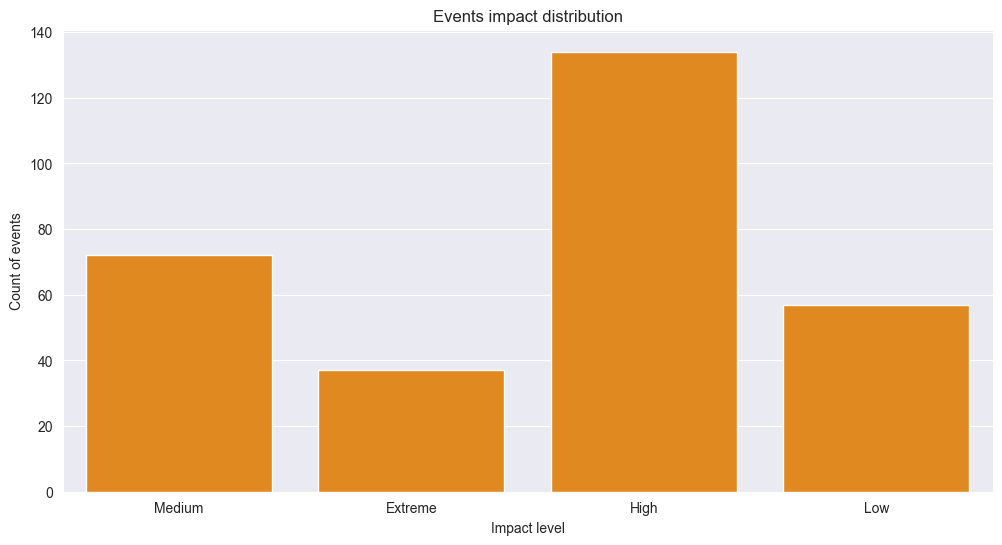

In [26]:
sns.countplot(df, x='event_impact_level', color='darkorange')
plt.title('Events impact distribution')
plt.xlabel('Impact level')
plt.ylabel('Count of events')

plt.show()

## Impact of events for every district

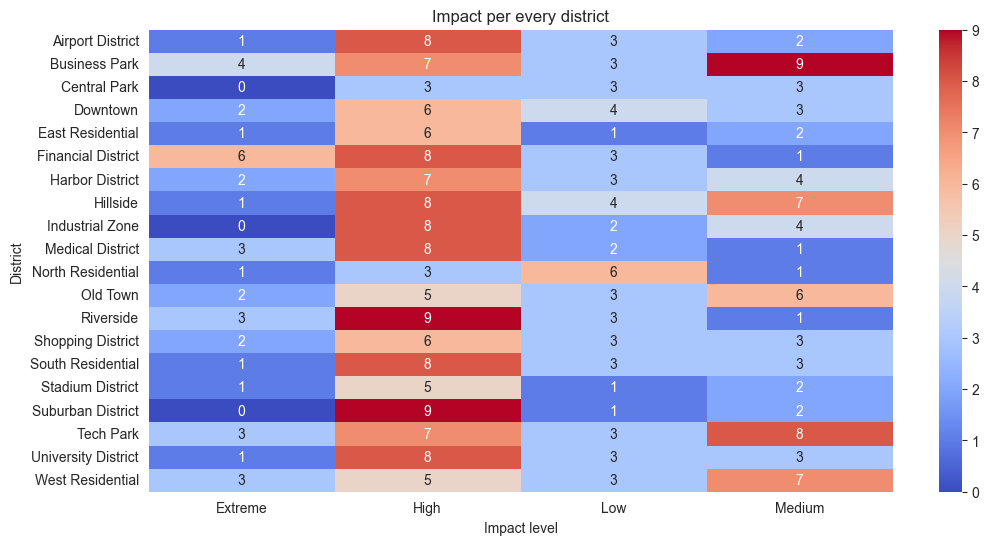

In [27]:
impact_per_district = districts_events.pivot_table(index='district_name', columns='event_impact_level', aggfunc='size', fill_value=0)

sns.heatmap(impact_per_district, annot=True, cmap='coolwarm')
plt.ylabel('District')
plt.xlabel('Impact level')
plt.title('Impact per every district')

plt.show()

## Duration distribution

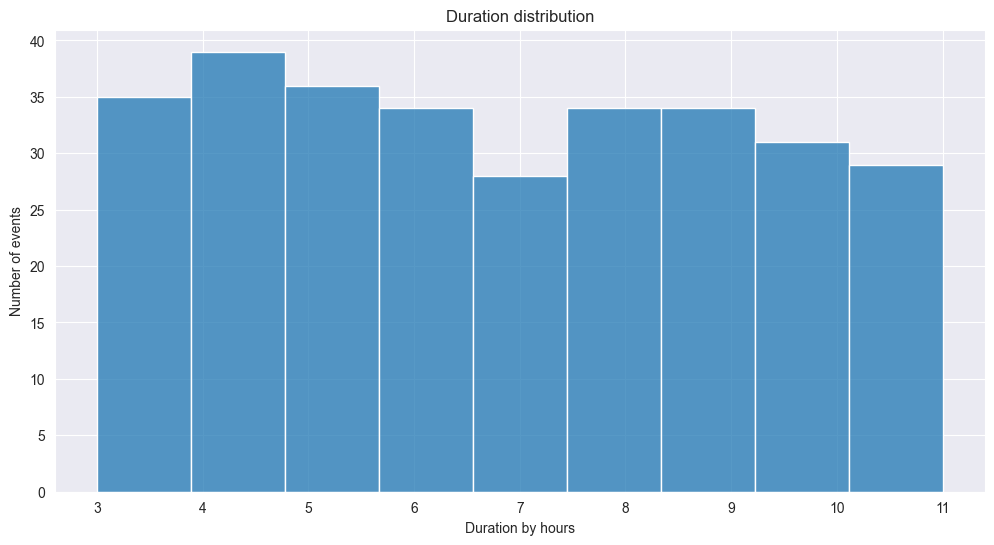

In [28]:
sns.histplot(df, x='duration_hours', bins=9)
plt.xlabel('Duration by hours')
plt.ylabel('Number of events')
plt.title('Duration distribution')

plt.show()